Convergence check on the radial grid resolution **`nr`** (number of DHT sample points, `nrs=[1000,2000,2500,3000,4000]`), at fixed `f#=20`, `L=15cm`. Plots the on-axis intensity profile for each `nr` to see how much the result changes with grid resolution.

Related notebooks: `axiconUR_sweep_L.ipynb` and `axiconUR_sweep_R.ipynb` sweep the physical parameters `L` and `R` instead of grid resolution.

Equations for the axiparabola are taken from:

M. V. Ambat, J. L. Shaw, J. J. Pigeon, K. G. Miller, T. T. Simpson, D. H. Froula, and J. P. Palastro, "Programmable-trajectory ultrafast flying focus pulses," Opt. Express 31, 31354-31368 (2023)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import jv

font = {"size": 26}

plt.rc("font", **font)
plt.rcParams["figure.figsize"] = (16, 9)
plt.rcParams["lines.linewidth"] = 4
plt.rcParams["legend.fontsize"] = 20

# The Discrete Hankel Transform

In [2]:
def DHTarrays(N, R, ell):
    Zeroes = np.genfromtxt("BesselZeroes" + str(ell) + ".csv")
    r = R * Zeroes[:N] / Zeroes[N - 1]
    k = Zeroes[:N] / R
    return np.array([r, k])

def DHTtransformMatrix(N, R, ell):
    Zeroes = np.genfromtxt("BesselZeroes" + str(ell) + ".csv")
    alpha = Zeroes[:N]
    kR = alpha[N - 1]
    kmax = kR / R
    T = (
        jv(ell, np.outer(alpha, alpha) / kR)
        / np.outer(abs(jv(ell + 1, alpha)), abs(jv(ell + 1, alpha)))
        / kR
    )
    # print(T)
    A = abs(jv(ell + 1, alpha))
    T_R2K = 4.0 * np.pi * (R / kmax) * T * A[:, None] / A[None, :]
    T_K2R = (1 / np.pi) * (kmax / R) * T * A[:, None] / A[None, :]

    return T_R2K, T_K2R

# Propagation

Propagates incident beam `phi_I` over `z` after reflecting from the mirror `zm`using DHT

In [3]:
def forward_propagation(k, phi_I, T_R2K, T_K2R, z, zm, wavelength):
    k0 = 2 * np.pi / wavelength
    phi_R0 = phi_I * np.exp(-2j * k0 * zm) #reflected profile from mirror

    # Hankel transform the field through multiplying by the appropriate transform matrix
    FT = T_R2K @ phi_R0
    # Propagate phi_R0 over z through multiplying phi_R0 by the diffractive phase:
    FT = FT * np.exp(-1j * k**2 / (2 * k0) * z[:, np.newaxis])
    # Inverse Hankel transform 𝐸̃ from 𝑘𝑟-space to 𝑟-space through multiplying by the inverse transform matrix
    fT = T_K2R @ (FT.T)

    return fT

# Sagitta Function
$s_f(r)=\frac{R^2}{4L}\ln\left[1+\frac{L}{f_0}\left(\frac{r}{R}\right)^2\right]$
or Taylor Expanded:
$s_f(r)\approx\frac{r^2}{4f_0}\left( 1-\frac{L}{f_0}(\frac{r}{R})^2\right)$

In [4]:
def create_axiparabola(r,R,L,f0,taylor=True):
    if taylor:
        sag = r**2/(4*f0)*(1-L/(2*f0)*(r/R)**2)
    else:
        sag = R**2/(4*L)*np.log(1+L/f0 *(r/R)**2)
    return sag

# Parameters

In [5]:
f = 0.5  # focal length of lens
fn=20
R = f/(2*fn)
ell = 0  # order of Bessel J function
wl=1e-6
k0 = 2 * np.pi / wl  # k=2*pi/wavelength
# L=[0.0, 1e-4, 1e-3, 1e-2, 5e-2]
L=15e-2
# zR = np.pi * w0**2 / wl  # Initial rayleigh length
# print(zR)
# print(wl*f**2/(np.pi*R**2))
nrs=[1000, 2000, 2500, 3000, 4000]
wf = 2 / np.pi *fn * wl
zR=wl*f**2/(np.pi*R**2)

print(R)
print(fn)
print(zR/1e-6)
print(4*fn**2*wl/np.pi/1e-6)
# print(R/nr)
print(wf/1e-6)
# print(R/nr < wf)

0.0125
20
509.2958178940651
509.2958178940651
12.732395447351628


In [6]:
z=np.linspace(f-0.1,f+L+0.1,1501)

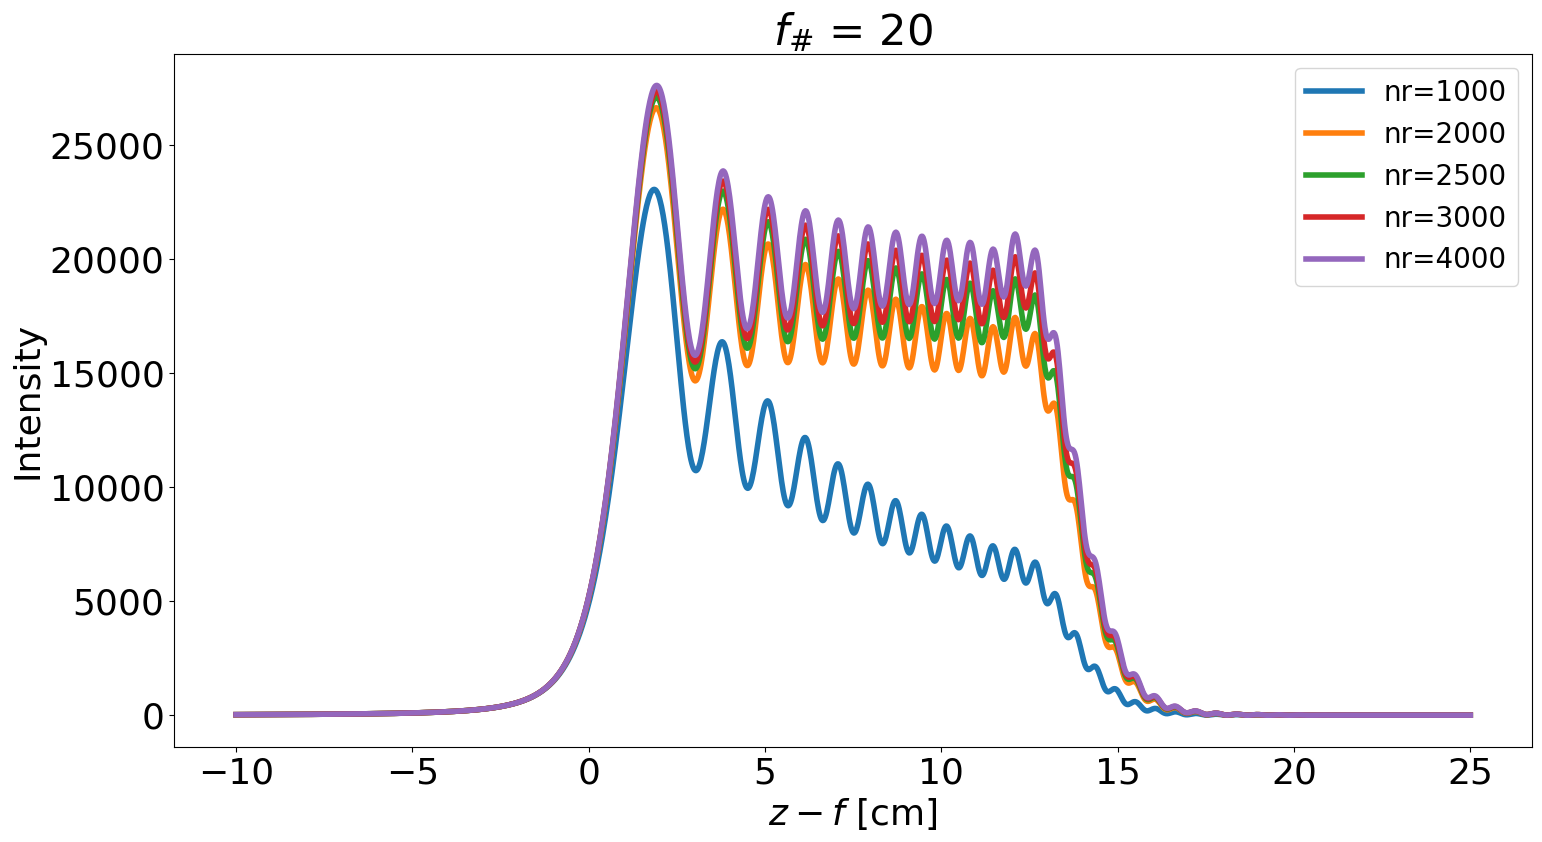

In [7]:
for nr in nrs:
    [r, k] = DHTarrays(nr, 1.3*R, ell)
    [T_R2K, T_K2R] = DHTtransformMatrix(nr, R, ell)
    phi_I=1j*np.exp(-((r / (R)) ** 40))
    z_mir=create_axiparabola(r,R,L,f,taylor=False)
    ftf=forward_propagation(k, phi_I, T_R2K, T_K2R, z, z_mir, wl)
    plt.plot((z-f)*100, np.abs(ftf[0,:])**2, label='nr='+str(nr))
    plt.xlabel(r'$z-f$ [cm]')
    plt.ylabel('Intensity')
plt.title(r'$f_\#$ = %d' % fn)
plt.legend()
plt.tight_layout()
# plt.savefig('nr_comp_f'+str(fn)+'.png')
plt.show()